### ORIE 5380 Course Project: Designing an In-Store Pilot Program

In the course project, you'll get experience formulating, testing, and analyzing models for decision support. We'll be exploring a scenario where you are an employee for an online retailer that is looking to partner with a chain of stores to offer in-store pickup and returns to reduce logistics costs. As offering the service requires store space and staff time, you want to pilot the program at *p* of the chain's *N* stores to reduce costs. In part 1, you'll design models that minimize the average and worst-case travel time for customers to a participating store. In part 2, you'll incorporate machine learning predictions to capture customer demand.

This project is an example of a class of optimization problems known as facility location problems. In a facility location problem, you want to decide where to locate facilities to best achieve a goal, like minimizing costs or maximizing utility. Other examples of facility location problems include selecting which airports an airline should select as hubs to minimize costs or selecting where to place fire stations to minimize response times.

You can work through this notebook similarly to the in-class introduction to Gurobi in Python. Information about the in-class Gurobi tutorial is available [here](https://canvas.cornell.edu/courses/88614/discussion_topics/1102292), including instructions on how to setup an academic Gurobi license.

In [1]:
# Import the packages needed to run the notebook
import numpy as np
import pandas as pd
import geopandas as gpd
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
import math

import gurobipy as gp
from gurobipy import GRB
from gurobipy import LinExpr

#### Test Your Gurobi Academic License

The models in this project are too large to run with the free Gurobi license. Follow the instructions [here](https://canvas.cornell.edu/courses/88614/discussion_topics/1102292) to setup a Gurobi Academic License. You must be on campus to activate your license. **Please ensure your license is setup well in advance of the project deadline.**

The cell below lets you test that your academic license is setup.

In [2]:
# Run this cell to test that your academic license works - you do not need to understand the model or submit anything
# from this cell for the project. If your academic license is **not** setup you will get an error: 
# GurobiError: Model too large for size-limited license
N = 100
c = np.random.rand(N,N)   

m0 = gp.Model('license_test')
x = m0.addVars(N,N, vtype=GRB.BINARY, name="x")     

for n in range(N):
    m0.addConstr(sum(x[n,j] for j in range(N)) == 1, name='row {}'.format(n))
    m0.addConstr(sum(x[i,n] for i in range(N)) == 1, name='col {}'.format(n))

m0.setObjective(sum(c[i,j] * x[i,j] for i in range(N) for j in range(N)), GRB.MINIMIZE)
m0.optimize()

Set parameter Username
Set parameter LicenseID to value 2878462
Academic license - for non-commercial use only - expires 2027-10-26
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 200 rows, 10000 columns and 20000 nonzeros (Min)
Model fingerprint: 0x9821dcb6
Model has 10000 linear objective coefficients
Variable types: 0 continuous, 10000 integer (10000 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-04, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective 53.3591869
Presolve time: 0.01s
Presolved: 200 rows, 10000 columns, 20000 nonzeros
Variable types: 0 continuous, 10000 integer (10000 binary)

Root relaxation: objective 1.484492e+00, 206 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objecti

### Part 1: Selecting Stores to Minimize Travel Time

In this section, you'll implement your models to minimize average and worst-case travel time and then visualize and interpret the solutions. You'll test the models on data for 36 stores and 3000 customers in the New York City area. Travel times are [OSRM](https://project-osrm.org/) traffic-free driving times between each customer-store pair. 

The code below to load the data assumes that you've downloaded and unzipped the data folder in the same directory as this notebook. You will need to adjust the filepaths if the data is in another location.

In [3]:
# Load data and set the range of p values we want to test
def read_points(path, **kwargs):
    df = pd.read_csv(path, **kwargs, index_col=0)
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326")

stores = read_points("data/stores.csv")
customers = read_points("data/customers.csv")
p_range = range(1,11)

The following block is the code to visualize the stores and customers on a map. You **do not** need to understand how this code works for the project or quiz, you just need to be able to call the `plot_map` using the instructions below.

`plot_map` takes the stores and customers dataframes and colors the points differently based on the arguments you pass to `solution_col`, `time_col`, and `color_by`:
- `plot_map(customer, stores)`: Plots a map of all customers and stores with fixed blue/grey coloring
- `plot_map(customers, stores, solution_col=SOLUTION_COL, color_by='store')`: Plots a map of selected stores, coloring customers by the store they are assigned to. The code assumes `stores[SOLUTION_COL]` has binary data on whether the store was selected and `customers[SOLUTION_COL]` has the store_id of the store assigned to that customer.
- `plot_map(customers, stores, solution_col=SOLUTION_COL, time_col=TIME_COL, color_by='time')`: Plots a map showing selected stores in red and coloring customers by the travel time to their assigned store. The code assumes `stores[SOLUTION_COL]` has binary data on whether the store was selected and `customers[TIME_COL]` has the travel time for each customer.

In [4]:
# Code to visualize stores and customers on a map
UNSELECTED = "#AEAEB2"   # unselected store color
SELECTED = "indianred"     # selected store color when showing continuous values for customers

# Return n colors from the seaborn deep palette, filtering out the grey which is too close 
# to the value for unselected stores
def store_colors(n):
    deep = [c for c in sns.color_palette("deep").as_hex() if c != "#8c8c8c"]
    return deep[:n] if n <= len(deep) else sns.blend_palette(deep, n_colors=n, as_cmap=False).as_hex()

def merc_y(lat):
    return math.log(math.tan(math.pi / 4 + math.radians(lat) / 2))

# Plot stores, using two markers to produce an 'outline'
def add_stores(fig, stores, color, size, name, outline="#8E8E93", showlegend=True, **kwargs):
    for marker, legend in [(dict(size=size + 3, color=outline), False), (dict(size=size, color=color), showlegend)]:
        fig.add_trace(go.Scattermap(
            lat=stores["latitude"], lon=stores["longitude"], mode="markers", marker=marker,
            name=name, legendgroup=name, showlegend=legend, hoverinfo="skip", **kwargs,
        ))

# Main function to plot customers and stores, see the text block above for instructions on how to produce different maps.
# Scale and pad to adjust the size and padding of the map relative to a 700px base cropped to the data's extent
def plot_map(customers, stores, solution_col=None, time_col=None, color_by="store", scale=0.7, pad=0.1):
    # Determine a bounding box to include all points with padding in Web Mercator
    lons = pd.concat([customers["longitude"], stores["longitude"]])
    lats = pd.concat([customers["latitude"], stores["latitude"]])
    x0, x1 = math.radians(lons.min()), math.radians(lons.max())
    y0, y1 = merc_y(lats.min()), merc_y(lats.max())
    x0, x1 = x0 - pad * (x1 - x0), x1 + pad * (x1 - x0)
    y0, y1 = y0 - pad * (y1 - y0), y1 + pad * (y1 - y0)

    # Calculate the size and center of the map
    height = round(700 * scale)
    width = round(height * (x1 - x0) / (y1 - y0))
    zoom = math.log2(height * 2 * math.pi / (512 * (y1 - y0)))  # map tiles are 512 px at zoom 0
    center = dict(lon=math.degrees((x0 + x1) / 2), lat=math.degrees(2 * math.atan(math.exp((y0 + y1) / 2)) - math.pi / 2))

    fig = go.Figure()
    if solution_col is None:
        # Basic map with just store and customer locations
        fig.add_trace(go.Scattermap(
            lat=customers["latitude"], lon=customers["longitude"], mode="markers",
            marker=dict(size=5, color=store_colors(1)[0], opacity=0.6),
            name="Customer", hoverinfo="skip",
        ))
        add_stores(fig, stores, UNSELECTED, 7, "Store")
    elif color_by == "time":
        # Map with selected stores in red and customers colored by travel time
        selected = stores[stores[solution_col] == 1]
        travel_time = customers[time_col]
        fig.add_trace(go.Scattermap(
            lat=customers["latitude"], lon=customers["longitude"], mode="markers",
            marker=dict(size=5, color=travel_time, colorscale="Viridis", cmin=0, opacity=0.8,
                        colorbar=dict(title=dict(text="Travel time (min)", side="right"), len=0.6, thickness=15)),
            name="Customer", hoverinfo="skip",
        ))
        add_stores(fig, selected, SELECTED, 7, "Selected store", outline="white")
    elif color_by == "store":
        # Map with discrete colormap for selected stores and customers colored by assigned store
        selected = stores[stores[solution_col] == 1]
        colors = store_colors(len(selected))

        # Plot unselected stores
        add_stores(fig, stores[stores[solution_col] == 0], UNSELECTED, 7, "Unselected store", legendrank=3)
        
        # Plot customers for each store
        for k, (color, store_id) in enumerate(zip(colors, selected.index)):
            served = customers[customers[solution_col] == store_id]
            fig.add_trace(go.Scattermap(
                lat=served["latitude"], lon=served["longitude"], mode="markers",
                marker=dict(size=5, color=color, opacity=0.6),
                name="Customer", legendgroup="Customer", showlegend=(k == 0), legendrank=1, hoverinfo="skip",
            ))
    
        # Plot selected stores over all customers 
        for k, (color, store_id) in enumerate(zip(colors, selected.index)):
            add_stores(fig, selected.loc[[store_id]], color, 9, "Selected store", outline="white",
                       showlegend=(k == 0), legendrank=2)
    else:
        raise ValueError(f'color_by must be "store" or "time", not {color_by!r}')

    right = 90 if solution_col is not None and color_by == "time" else 0  # room for the colorbar beside the map
    fig.update_layout(
        map=dict(style="carto-positron", center=center, zoom=zoom),
        width=width + right, height=height, margin=dict(l=0, r=right, t=0, b=0),
        legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.8)"),
    )
    return fig

In [5]:
# Use plot_map to visualize all stores and customers
plot_map(customers, stores).show()

In [6]:
# Format data for the optimization
MAX_TIME = 60
results = {}

M = customers.shape[0]  # use i for customers
N = stores.shape[0]     # use j for stores

# t is a M x N matrix where t[i,j] is the travel time for customer i to travel to store j
t = customers[['d{}'.format(i) for i in range(stores.shape[0])]].to_numpy()

#### Model 1: Minimize Average Customer Travel Time

In [7]:
# In this cell, implement your model to minimize the average customer travel time
# Once you are happy with your model for a single value of p, copy the code to the loop in the following cell 
# to optimize for p = 1, ..., 10 and collect solution values


model_name = 'mean-dist'
p = 3

m1 = gp.Model(model_name)

# TODO: Implement your model
# ---------------------------------------------------------------------------
# CONSTRUCT DECISION VARIABLES
# constructed binary variables x_ij for  whether facility location i is 
#   connected to customer location j, and
# binary variables y_j for whether potential facility location j is open
# then update model with the variables
# ---------------------------------------------------------------------------
xVars = m1.addVars(M, N, vtype=GRB.BINARY, name="x") 
yVars = m1.addVars(N, vtype=GRB.BINARY, name="y")

m1.update()

In [8]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTIVE FUNCTION
# constructed objective function to maximize the total population covered 
#   by the selected facilities
# did this by first creating empty expression for objective function, then 
#   adding the product of the population of each customer location and 
#   the corresponding binary variable y_j
# then update the model with the objective function
# ---------------------------------------------------------------------------
objExpr = LinExpr()
for i in range ( M ):
    for j in range( N ):
        objExpr += t[ i , j ] * xVars[ i , j ]
m1.setObjective( objExpr / M , GRB.MINIMIZE )
m1.update()

In [9]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed three sets of contraints.
#   the first being the assignment constraints which ensures that  
#       the number of connections between a single customer
#       over all facility locations is 1
#   the second being the cardinality constraint which ensures that 
#       the total number of selected facility locations equals the bound
#   the third being the linking contraint which ensures
#       that a customer can only be connected to a facility which is open (1)
# then update the model with the constraints 
# ---------------------------------------------------------------------------

for i in range( M ):
    constrExpr = LinExpr()  # new expression for each customer 
    for j in range( N ):
        constrExpr += xVars[ i , j ]
    m1.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )

constrExpr = LinExpr()      # one big expression for the whole sum
for j in range( N ):
    constrExpr += yVars[ j ]
m1.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )

for i in range( M ):
    for j in range( N ):
        m1.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )

m1.update()

In [10]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# returns the initialized data, 
#   constructs the model, 
#   writes the model to a file, 
#   optimizes the model, and 
#   prints the solution
# ---------------------------------------------------------------------------
# Set time limit
m1.setParam('time_limit', MAX_TIME)
m1.write( "november_13_2026_mean_dist.lp")

Set parameter TimeLimit to value 60


In [11]:
# Optimize
m1.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Min)
Model fingerprint: 0xab1b8893
Model has 107999 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [7e-05, 2e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]

Presolve time: 0.22s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Found heuristic solution: objective 17.5501667
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only...


Root simplex log...

Iteration    Objective       Primal Inf.    Dual Inf.      Time
   48099    1.2183350e+01   0.000000e+

In [12]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print optimal objective value and the values of the decision variables x_ij and y_j
# ---------------------------------------------------------------------------

print("Opt. Obj. " + str(m1.ObjVal))
for j in range(N):
    if yVars[j].X > 0.5:
        print(yVars[j].VarName, yVars[j].X)

Opt. Obj. 11.646233333333331
y[1] 1.0
y[7] 1.0
y[23] 1.0


In [13]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'mean-dist'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))
    # TODO: Copy your model code from the previous cell
    
    # decision variables
    m1 = gp.Model(model_name)       # empty model for first p
    xVars = m1.addVars(M, N, vtype=GRB.BINARY, name="x") 
    yVars = m1.addVars(N, vtype=GRB.BINARY, name="y")
    m1.update()

    # objective
    objExpr = LinExpr()
    for i in range ( M ):
        for j in range( N ):
            objExpr += t[ i , j ] * xVars[ i , j ]
    m1.setObjective( objExpr / M , GRB.MINIMIZE )
    m1.update()

    # constraints
    for i in range( M ):
        constrExpr = LinExpr()  # new expression for each customer 
        for j in range( N ):
            constrExpr += xVars[ i , j ]
        m1.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )
    constrExpr = LinExpr()      # one big expression for the whole sum
    for j in range( N ):
        constrExpr += yVars[ j ]
    m1.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )
    for i in range( M ):
        for j in range( N ):
            m1.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )
    m1.update()

    # optimize
    m1.setParam('time_limit', MAX_TIME)
    m1.optimize()
    
    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = [ 1 if yVars[j].X > 0.5 else 0 for j in range(N)]

    # TODO: Add a column to the customers dataframe with the store_id of the closest selected store
    customers[soln_col] = [ stores.index[j] for i in range(M) for j in range(N) if xVars[ i , j].X > 0.5 ]

    # TODO: Add a column to the customers dataframe for the minimum travel time for each customer
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = [ t[i, j] for i in range(M) for j in range(N) if xVars[ i , j].X > 0.5 ]

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime and objective value
    results[model_name, p] = {"runtime_s": m1.Runtime, "gap_percent": m1.MIPGap * 100, "objective": m1.ObjVal,
                              "mean_time": customers[time_col].mean(), "max_time": customers[time_col].max()}


------------------------------
Starting p = 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Min)
Model fingerprint: 0xdbf1c073
Model has 107999 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [7e-05, 2e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.35s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Found heuristic solution: objective 19.3053000
Found heuristic solution: objective 19.0831333
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only

#### Model 2: Minimize Worst-Case Customer Travel Time

In [14]:
# In this cell, implement your model to minimize the worst-case customer travel time
# Once you are happy with your model for a single value of p, copy the code to the loop in the next cell 
# to optimize over p = 1, ..., 10 and collect solution values
model_name = 'max-dist'
p = 3

m2 = gp.Model(model_name)

# TODO: Implement your model
# ---------------------------------------------------------------------------
# CONSTRUCT DECISION VARIABLES
# constructed binary variables x_ij for  whether facility location i is 
#   connected to customer location j, and
# binary variables y_j for whether potential facility location j is open
# then update model with the variables
# ---------------------------------------------------------------------------
xVars = m2.addVars(M, N, vtype=GRB.BINARY, name="x") 
yVars = m2.addVars(N, vtype=GRB.BINARY, name="y")
w = m2.addVar(vtype=GRB.CONTINUOUS, name="w")

m2.update()


In [15]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTIVE FUNCTION
# constructed objective function to minimize the worst-case customer travel time
# did this by putting w in the objective
# then update the model with the objective function
# --------------------------------------------------------------------------- 
m2.setObjective( w , GRB.MINIMIZE )
m2.update()

In [16]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed four sets of contraints.
#   the first being the maximization constraint which ensures that  
#       w is the maximum time traveled between any single customer and facility
#   the second being the assignment constraints which ensures that  
#       the number of connections between a single customer
#       over all facility locations is 1
#   the third being the cardinality constraint which ensures that 
#       the total number of selected facility locations equals the bound
#   the fourth being the linking contraint which ensures
#       that a customer can only be connected to a facility which is open (1)
# then update the model with the constraints 
# ---------------------------------------------------------------------------

for i in range ( M ):
    constrExpr = LinExpr()
    for j in range ( N ):
        constrExpr += t[ i , j ] * xVars[ i , j ]
    # one constraint per customer
    m2.addLConstr( lhs = constrExpr , sense = GRB.LESS_EQUAL , rhs = w , name = "worst_case_" + str( i ) )
        

for i in range( M ):
    constrExpr = LinExpr()  # new expression for each customer 
    for j in range( N ):
        constrExpr += xVars[ i , j ]
    m2.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )

constrExpr = LinExpr()      # one big expression for the whole sum
for j in range( N ):
    constrExpr += yVars[ j ]
m2.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )

for i in range( M ):
    for j in range( N ):
        m2.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )

m2.update()

In [17]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# returns the initialized data, 
#   constructs the model, 
#   writes the model to a file, 
#   optimizes the model, and 
#   prints the solution
# ---------------------------------------------------------------------------
# Set time limit
m2.setParam('time_limit', MAX_TIME)
m2.write( "november_13_2026_max-dist.lp")

Set parameter TimeLimit to value 60


In [18]:
# Optimize
m2.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 114001 rows, 108037 columns and 435035 nonzeros (Min)
Model fingerprint: 0x88a3f5f1
Model has 1 linear objective coefficients
Variable types: 1 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [2e-01, 7e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]

Presolve removed 1330 rows and 1260 columns
Presolve time: 0.60s
Presolved: 112671 rows, 106777 columns, 365161 nonzeros
Variable types: 0 continuous, 106777 integer (106776 binary)
Found heuristic solution: objective 59.3000000
Found heuristic solution: objective 59.1000000
Found heuristic solution: objective 58.2000000
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log 

In [19]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'max-dist'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))
    # TODO: Copy your model code from the previous cell

    m2 = gp.Model(model_name)       # empty model for first p
    xVars = m2.addVars(M, N, vtype=GRB.BINARY, name="x") 
    yVars = m2.addVars(N, vtype=GRB.BINARY, name="y")
    w = m2.addVar(vtype=GRB.CONTINUOUS, name="w")
    m2.update()

    m2.setObjective( w , GRB.MINIMIZE )
    m2.update()

    for i in range ( M ):
        constrExpr = LinExpr()
        for j in range ( N ):
            constrExpr += t[ i , j ] * xVars[ i , j ]
    # one constraint per customer
        m2.addLConstr( lhs = constrExpr , sense = GRB.LESS_EQUAL , rhs = w , name = "worst_case_" + str( i ) )
    for i in range( M ):
        constrExpr = LinExpr()  # new expression for each customer 
        for j in range( N ):
            constrExpr += xVars[ i , j ]
        m2.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )
    constrExpr = LinExpr()      # one big expression for the whole sum
    for j in range( N ):
        constrExpr += yVars[ j ]
    m2.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )
    for i in range( M ):
        for j in range( N ):
            m2.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )
    m2.update()

    m2.setParam('time_limit', MAX_TIME)
    m2.optimize()

    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = [ 1 if yVars[j].X > 0.5 else 0 for j in range(N)]

    # TODO: Add a column to the customers dataframe for the closest selected store to each customer
    soln_col = '{}-p{}'.format(model_name, p)
    customers[soln_col] = [ stores.index[j] for i in range(M) for j in range(N) if xVars[ i , j].X > 0.5 ]

    # TODO: Add a column to the customers dataframe for the minimum travel time for each customer
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = [ t[i, j] for i in range(M) for j in range(N) if xVars[ i , j].X > 0.5 ]

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime or objective value
    results[model_name, p] = {"runtime_s": m2.Runtime, "gap_percent": m2.MIPGap * 100, "objective": m2.ObjVal,
                              "mean_time": customers[time_col].mean(), "max_time": customers[time_col].max()}

------------------------------
Starting p = 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 114001 rows, 108037 columns and 435035 nonzeros (Min)
Model fingerprint: 0x812c09eb
Model has 1 linear objective coefficients
Variable types: 1 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [2e-01, 7e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Presolve removed 1346 rows and 1276 columns
Presolve time: 1.11s
Presolved: 112655 rows, 106761 columns, 365129 nonzeros
Variable types: 0 continuous, 106761 integer (106760 binary)
Found heuristic solution: objective 58.2000000
Found heuristic solution: objective 55.0000000
Deterministic concurrent LP optimizer: primal a

#### Visualize and Interpret Solutions

In [20]:
# Combine results into a dataframe
results_df = pd.DataFrame.from_dict(results, orient="index").rename_axis(["model", "p"]).sort_index()
results_df

runtime_s  gap_percent  objective  mean_time  max_time
model     p                                                         
max-dist  1    6.757265          0.0  45.800000  18.968800      45.8
          2   10.933107          0.0  35.900000  17.616633      35.9
          3   10.071976          0.0  27.300000  16.612067      27.3
          4   13.384820          0.0  26.000000  16.495933      26.0
          5    2.275629          0.0  25.400000  15.240267      25.4
          6    2.533573          0.0  25.400000  16.512000      25.4
          7    2.007825          0.0  25.400000  16.421967      25.4
          8    1.852642          0.0  25.400000  16.574067      25.4
          9    1.605810          0.0  25.400000  16.796867      25.4
          10   1.200980          0.0  25.400000  16.925400      25.4
mean-dist 1    6.054207          0.0  18.118133  18.118133      56.0
          2    5.484583          0.0  13.576400  13.576400      42.5
          3   13.646512          0.0  11.646233  11.646233      42.5
          4    3.582443          0.0   9.975867   9.975867      42.5
          5    3.293801          0.0   9.289367   9.289367      31.7
          6    3.042272          0.0   8.638700   8.638700      31.7
          7    5.557372          0.0   8.240300   8.240300      31.7
          8    2.525579          0.0   7.868267   7.868267      29.4
          9    2.180315          0.0   7.544033   7.544033      29.4
          10   2.119232          0.0   7.335367   7.335367      29.4

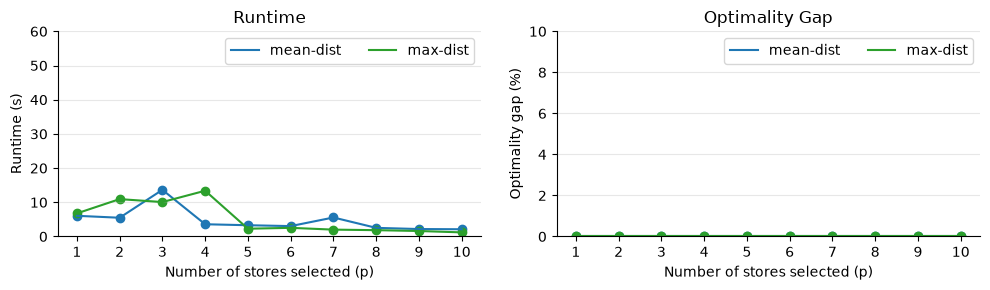

In [21]:
# The code below produces a plot of runtime and optimality gap for each model and value of p
# TODO: Change the constants below to the correct columns in results_df for runtime and optimality gap, 
#       changing the title/labels if your columns use different units
RUNTIME_COL = 'runtime_s'
OPTGAP_COL = 'gap_percent'

RUNTIME_TITLE, RUNTIME_YLABEL, RUNTIME_XLABEL = ('Runtime', 'Runtime (s)', 'Number of stores selected (p)')
OPTGAP_TITLE, OPTGAP_YLABEL, OPTGAP_XLABEL = ('Optimality Gap', 'Optimality gap (%)', 'Number of stores selected (p)')

# Model colormap
model_colors = {"mean-dist": "tab:blue", "max-dist": "tab:green"}

# Axes formatting and labels
def format_plot(title, ylabel, xlabel, legend_bbox=None):
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xlabel(xlabel)
    plt.xticks(p_range)
    if legend_bbox != None:
        plt.legend(ncol=2, bbox_to_anchor=legend_bbox)
    else:
        plt.legend(ncol=2)

    ax = plt.gca()
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()

# Create the figure
fig = plt.figure(figsize=(10,3))

# Runtime subplot
plt.subplot(1,2,1)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[RUNTIME_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[RUNTIME_COL], color=model_colors[model])

format_plot(title=RUNTIME_TITLE, ylabel=RUNTIME_YLABEL, xlabel=RUNTIME_XLABEL)
plt.ylim([0,60])

# Optimality gap subplot
plt.subplot(1,2,2)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[OPTGAP_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[OPTGAP_COL], color=model_colors[model])

format_plot(title=OPTGAP_TITLE, ylabel=OPTGAP_YLABEL, xlabel=OPTGAP_XLABEL)
plt.ylim([0,10])
plt.show()

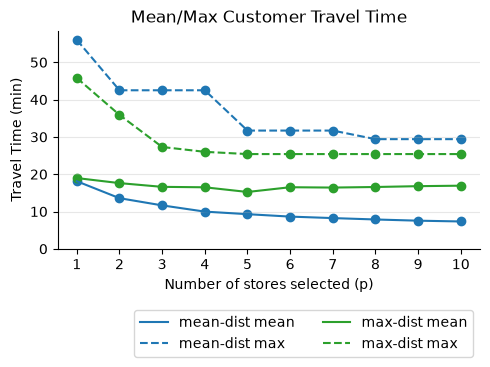

In [22]:
# The code below produces a plot of average and worst-case customer travel distance for each model and value of p
# TODO: Change the constants below to the correct columns in results_df for average and max travel distance 
#       changing the title/labels if your columns use different units
MEAN_DIST_COL = 'mean_time'
MAX_DIST_COL = 'max_time'

DIST_TITLE, DIST_YLABEL, DIST_XLABEL = ('Mean/Max Customer Travel Time', 'Travel Time (min)', 'Number of stores selected (p)')

# Create the figure
fig = plt.figure(figsize=(5,4))
for model in model_colors.keys():
    res = results_df.loc[model]

    # Average customer travel time
    plt.plot(res.index, res[MEAN_DIST_COL], color=model_colors[model], linestyle='-', label='{} mean'.format(model))
    plt.scatter(res.index, res[MEAN_DIST_COL], color=model_colors[model])

    # Worst-case customer travel time
    plt.plot(res.index, res[MAX_DIST_COL], color=model_colors[model], linestyle='--', label='{} max'.format(model))
    plt.scatter(res.index, res[MAX_DIST_COL], color=model_colors[model])

format_plot(title=DIST_TITLE, ylabel=DIST_YLABEL, xlabel=DIST_XLABEL, legend_bbox=(1, -0.25))
plt.show()

In [23]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
# You can uncomment the line below to save a png of the map for your report
SOLUTION_COL = 'mean-dist-p10'

fig = plot_map(customers, stores, solution_col=SOLUTION_COL)
# fig.write_image('fig.png', scale=2)
fig.show()

In [24]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
SOLUTION_COL = 'mean-dist-p10'
TIME_COL = 'mean-dist-p10-time'

fig = plot_map(customers, stores, solution_col=SOLUTION_COL, time_col=TIME_COL, color_by="time")
fig.show()

### Part 2: Selecting Stores Based on Customer Usage

In this section, you'll implement and analyze two models incorporating machine learning predictions to select locations incorporating customer demand.

In [25]:
# Load and format predictions for the optimization
predictions = pd.read_csv('data/customer-predictions.csv', index_col=0)
store_predictions = pd.read_csv('data/customer-store-predictions.csv', index_col=0)

P = predictions[['p']].to_numpy().reshape((M))                          # P[i] is the predicted probability that customer i uses the service at any location
Ps = store_predictions[['p{}'.format(i) for i in range(N)]].to_numpy()  # Ps[i,j] is the predicted probability the customer i uses the service at location j

#### Model 3: Minimize Expected Customer Travel Time

In [26]:
# In this cell, implement your model to minimize the expected customer travel time
# Once you are happy with your model for a single value of p, copy the code to the loop in the following cell
# to optimize for p = 1, ..., 10 and collect solution values
model_name = 'min-exp-dist'
p = 3

m3 = gp.Model(model_name)

# ---------------------------------------------------------------------------
# CONSTRUCT DECISION VARIABLES
# constructed binary variables x_ij for whether customer i is
#   assigned to store j, and
# binary variables y_j for whether store j is open
# then update model with the variables
# ---------------------------------------------------------------------------
xVars = m3.addVars(M, N, vtype=GRB.BINARY, name="x")
yVars = m3.addVars(N, vtype=GRB.BINARY, name="y")

m3.update()

In [27]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTIVE FUNCTION
# constructed objective function to minimize the expected customer travel time
#   (1/M) * sum_i P_i * sum_j t_ij * x_ij
# where P_i is the predicted probability customer i uses the service at all
# then update the model with the objective function
# ---------------------------------------------------------------------------
objExpr = LinExpr()
for i in range ( M ):
    for j in range( N ):
        objExpr += P[ i ] * t[ i , j ] * xVars[ i , j ]
m3.setObjective( objExpr / M , GRB.MINIMIZE )
m3.update()

In [28]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed three sets of contraints.
#   the first being the assignment constraints which ensures that
#       each customer is assigned to exactly one store
#   the second being the cardinality constraint which ensures that
#       the total number of open stores equals p
#   the third being the linking contraint which ensures
#       that a customer can only be assigned to a store which is open (1)
# then update the model with the constraints
# ---------------------------------------------------------------------------

for i in range( M ):
    constrExpr = LinExpr()  # new expression for each customer
    for j in range( N ):
        constrExpr += xVars[ i , j ]
    m3.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )

constrExpr = LinExpr()      # one big expression for the whole sum
for j in range( N ):
    constrExpr += yVars[ j ]
m3.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )

for i in range( M ):
    for j in range( N ):
        m3.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )

m3.update()

In [29]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# sets the time limit, writes the model to a file, and optimizes the model
# ---------------------------------------------------------------------------
# Set time limit
m3.setParam('time_limit', MAX_TIME)
m3.write( "november_25_2026_min-exp-dist.lp")

# Optimize
m3.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Min)
Model fingerprint: 0x7fde486c
Model has 107999 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-05, 1e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]

Presolve time: 0.22s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Found heuristic solution: objective 3.8228261
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only...

Concurrent spin time: 0.00s

Solved with dual simplex

Root relaxation: objective 2.24045

In [30]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print optimal objective value and the open stores y_j
# ---------------------------------------------------------------------------

print("Opt. Obj. " + str(m3.ObjVal))
for j in range(N):
    if yVars[j].X > 0.5:
        print(yVars[j].VarName, yVars[j].X)

Opt. Obj. 2.240454193333338
y[5] 1.0
y[7] 1.0
y[23] 1.0


In [31]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'min-exp-dist'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))

    # decision variables
    m3 = gp.Model(model_name)       # empty model for each p
    xVars = m3.addVars(M, N, vtype=GRB.BINARY, name="x")
    yVars = m3.addVars(N, vtype=GRB.BINARY, name="y")
    m3.update()

    # objective
    objExpr = LinExpr()
    for i in range ( M ):
        for j in range( N ):
            objExpr += P[ i ] * t[ i , j ] * xVars[ i , j ]
    m3.setObjective( objExpr / M , GRB.MINIMIZE )
    m3.update()

    # constraints
    for i in range( M ):
        constrExpr = LinExpr()  # new expression for each customer
        for j in range( N ):
            constrExpr += xVars[ i , j ]
        m3.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )
    constrExpr = LinExpr()      # one big expression for the whole sum
    for j in range( N ):
        constrExpr += yVars[ j ]
    m3.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )
    for i in range( M ):
        for j in range( N ):
            m3.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )
    m3.update()

    # optimize
    m3.setParam('time_limit', MAX_TIME)
    m3.optimize()

    # store index j each customer i was assigned to
    assigned = [ j for i in range(M) for j in range(N) if xVars[ i , j ].X > 0.5 ]

    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = [ 1 if yVars[j].X > 0.5 else 0 for j in range(N)]

    # TODO: Add a column to the customers dataframe for the closest selected store to each customer
    soln_col = '{}-p{}'.format(model_name, p)
    customers[soln_col] = [ stores.index[ assigned[i] ] for i in range(M) ]

    # TODO: Add a column to the customers dataframe for the minimum travel time for each customer
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = [ t[ i , assigned[i] ] for i in range(M) ]

    # Evaluation metrics, computed the same way for both Part 2 models so they can be compared
    #   exp_customers: expected # customers using the service = sum_i Ps[i, assigned store]
    #   exp_mean_time: average travel time weighted by usage probability P_i = sum_i P_i * t_i / sum_i P_i
    #   max_time:      worst-case travel time to the assigned store
    exp_customers = sum( Ps[ i , assigned[i] ] for i in range(M) )
    exp_mean_time = sum( P[i] * t[ i , assigned[i] ] for i in range(M) ) / sum( P )
    max_time = max( t[ i , assigned[i] ] for i in range(M) )

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime or objective value
    results[model_name, p] = {"runtime_s": m3.Runtime, "gap_percent": m3.MIPGap * 100, "objective": m3.ObjVal,
                              "exp_customers": exp_customers, "exp_mean_time": exp_mean_time, "max_time": max_time}

------------------------------
Starting p = 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Min)
Model fingerprint: 0xb4d1b91e
Model has 107999 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-05, 1e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.39s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Found heuristic solution: objective 4.1310173
Found heuristic solution: objective 3.9813641
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only..

#### Model 4: Maximize Expected Usage

In [32]:
# In this cell, implement your model to maximize the expected number of customer using the in-store service
# Once you are happy with your model for a single value of p, copy the code to the loop in the following cell
# to optimize for p = 1, ..., 10 and collect solution values
model_name = 'max-exp-usage'
p = 3

m4 = gp.Model(model_name)

# ---------------------------------------------------------------------------
# CONSTRUCT DECISION VARIABLES
# constructed binary variables x_ij for whether customer i is
#   assigned to store j, and
# binary variables y_j for whether store j is open
# then update model with the variables
# ---------------------------------------------------------------------------
xVars = m4.addVars(M, N, vtype=GRB.BINARY, name="x")
yVars = m4.addVars(N, vtype=GRB.BINARY, name="y")

m4.update()

In [33]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTIVE FUNCTION
# constructed objective function to maximize the expected number of customers
#   using the service: sum_i sum_j Ps_ij * x_ij
# where Ps_ij is the predicted probability customer i uses the service at store j
# then update the model with the objective function
# ---------------------------------------------------------------------------
objExpr = LinExpr()
for i in range ( M ):
    for j in range( N ):
        objExpr += Ps[ i , j ] * xVars[ i , j ]
m4.setObjective( objExpr , GRB.MAXIMIZE )
m4.update()

In [34]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
# constructed three sets of contraints.
#   the first being the assignment constraints which ensures that
#       each customer is assigned to exactly one store
#   the second being the cardinality constraint which ensures that
#       the total number of open stores equals p
#   the third being the linking contraint which ensures
#       that a customer can only be assigned to a store which is open (1)
# then update the model with the constraints
# ---------------------------------------------------------------------------

for i in range( M ):
    constrExpr = LinExpr()  # new expression for each customer
    for j in range( N ):
        constrExpr += xVars[ i , j ]
    m4.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )

constrExpr = LinExpr()      # one big expression for the whole sum
for j in range( N ):
    constrExpr += yVars[ j ]
m4.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )

for i in range( M ):
    for j in range( N ):
        m4.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )

m4.update()

In [35]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# sets the time limit, writes the model to a file, and optimizes the model
# ---------------------------------------------------------------------------
# Set time limit
m4.setParam('time_limit', MAX_TIME)
m4.write( "november_25_2026_max-exp-usage.lp")

# Optimize
m4.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Max)
Model fingerprint: 0x3d076c67
Model has 95171 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e-04, 5e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]

Presolve time: 0.23s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Found heuristic solution: objective 3.9359000
Found heuristic solution: objective 9.0346000
Found heuristic solution: objective 9.0627000
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only...

In [36]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print optimal objective value and the open stores y_j
# ---------------------------------------------------------------------------

print("Opt. Obj. " + str(m4.ObjVal))
for j in range(N):
    if yVars[j].X > 0.5:
        print(yVars[j].VarName, yVars[j].X)

Opt. Obj. 41.69689999999993
y[8] 1.0
y[15] 1.0
y[19] 1.0


In [37]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'max-exp-usage'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))

    # decision variables
    m4 = gp.Model(model_name)       # empty model for each p
    xVars = m4.addVars(M, N, vtype=GRB.BINARY, name="x")
    yVars = m4.addVars(N, vtype=GRB.BINARY, name="y")
    m4.update()

    # objective
    objExpr = LinExpr()
    for i in range ( M ):
        for j in range( N ):
            objExpr += Ps[ i , j ] * xVars[ i , j ]
    m4.setObjective( objExpr , GRB.MAXIMIZE )
    m4.update()

    # constraints
    for i in range( M ):
        constrExpr = LinExpr()  # new expression for each customer
        for j in range( N ):
            constrExpr += xVars[ i , j ]
        m4.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = 1 , name = "assignment_" + str( i ) )
    constrExpr = LinExpr()      # one big expression for the whole sum
    for j in range( N ):
        constrExpr += yVars[ j ]
    m4.addLConstr( lhs = constrExpr , sense = GRB.EQUAL , rhs = p , name = "cardinality_" + str( p ) )
    for i in range( M ):
        for j in range( N ):
            m4.addLConstr( lhs = xVars[ i , j ] , sense = GRB.LESS_EQUAL , rhs = yVars[ j ] , name = "linking_" + str( i ) + "_" + str( j ) )
    m4.update()

    # optimize
    m4.setParam('time_limit', MAX_TIME)
    m4.optimize()

    # store index j each customer i was assigned to
    assigned = [ j for i in range(M) for j in range(N) if xVars[ i , j ].X > 0.5 ]

    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = [ 1 if yVars[j].X > 0.5 else 0 for j in range(N)]

    # TODO: Add a column to the customers dataframe for the store the customer was assigned to
    soln_col = '{}-p{}'.format(model_name, p)
    customers[soln_col] = [ stores.index[ assigned[i] ] for i in range(M) ]

    # TODO: Add a column to the customers dataframe for the travel time to the store the customer was assigned to
    #       Note: In this model the customer may not go to the nearest store
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = [ t[ i , assigned[i] ] for i in range(M) ]

    # Evaluation metrics, computed the same way for both Part 2 models so they can be compared
    #   exp_customers: expected # customers using the service = sum_i Ps[i, assigned store]
    #   exp_mean_time: average travel time weighted by usage probability P_i = sum_i P_i * t_i / sum_i P_i
    #   max_time:      worst-case travel time to the assigned store
    exp_customers = sum( Ps[ i , assigned[i] ] for i in range(M) )
    exp_mean_time = sum( P[i] * t[ i , assigned[i] ] for i in range(M) ) / sum( P )
    max_time = max( t[ i , assigned[i] ] for i in range(M) )

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime or objective value
    results[model_name, p] = {"runtime_s": m4.Runtime, "gap_percent": m4.MIPGap * 100, "objective": m4.ObjVal,
                              "exp_customers": exp_customers, "exp_mean_time": exp_mean_time, "max_time": max_time}

------------------------------
Starting p = 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Max)
Model fingerprint: 0x49df9eed
Model has 95171 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e-04, 5e-01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.39s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Found heuristic solution: objective 9.0258000
Found heuristic solution: objective 12.4307000
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only..

#### Visualize and Interpret Solutions

In [38]:
# Combine results into a dataframe
results_df = pd.DataFrame.from_dict(results, orient="index").rename_axis(["model", "p"]).sort_index()
results_df.loc[["min-exp-dist", "max-exp-usage"]]

runtime_s  gap_percent  objective  mean_time  max_time  \
model         p                                                            
min-exp-dist  1    6.142012          0.0   3.586694        NaN      52.0   
              2    4.270792          0.0   2.577457        NaN      42.5   
              3    4.086436          0.0   2.240454        NaN      42.5   
              4    3.282952          0.0   1.988536        NaN      42.5   
              5    2.852013          0.0   1.777543        NaN      42.5   
              6    2.571208          0.0   1.651968        NaN      31.7   
              7    2.560379          0.0   1.571844        NaN      31.7   
              8    7.685475          0.0   1.501505        NaN      31.7   
              9    2.304789          0.0   1.433728        NaN      29.4   
              10   2.073121          0.0   1.384832        NaN      29.4   
max-exp-usage 1    4.515196          0.0  20.937700        NaN      47.9   
              2    3.831060          0.0  33.964500        NaN      48.1   
              3    2.288756          0.0  41.696900        NaN      43.2   
              4    2.709521          0.0  48.016700        NaN      46.7   
              5    2.193912          0.0  52.478100        NaN      46.7   
              6    3.524409          0.0  55.927100        NaN      46.7   
              7    3.738632          0.0  59.070000        NaN      46.7   
              8    3.214567          0.0  61.876200        NaN      46.7   
              9    4.895979          0.0  64.204900        NaN      46.7   
              10   3.042822          0.0  66.324000        NaN      46.7   

                  exp_customers  exp_mean_time  
model         p                                 
min-exp-dist  1          8.7097      16.767029  
              2         12.9276      12.049060  
              3         14.6233      10.473646  
              4         21.6665       9.295980  
              5         27.6796       8.309634  
              6         28.7102       7.722597  
              7         30.4763       7.348035  
              8         35.1004       7.019216  
              9         35.5796       6.702371  
              10        41.7470       6.473796  
max-exp-usage 1         20.9377      17.310809  
              2         33.9645      15.372977  
              3         41.6969      13.074816  
              4         48.0167      13.493063  
              5         52.4781      13.346646  
              6         55.9271      11.945268  
              7         59.0700      10.730888  
              8         61.8762      10.322553  
              9         64.2049      10.006205  
              10        66.3240      10.015476

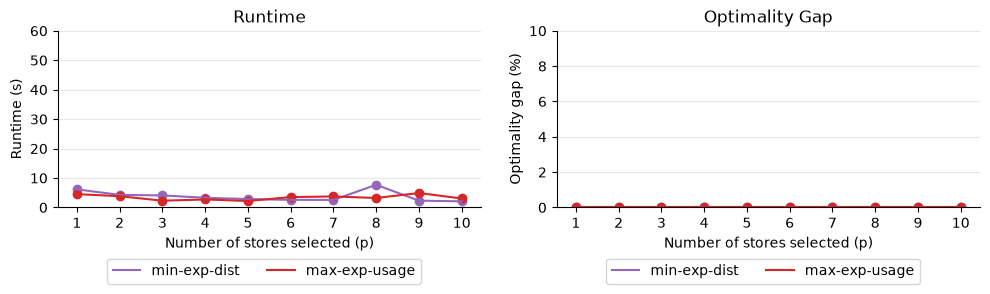

In [39]:
# The code below produces a plot of runtime and optimality gap for each model and value of p
# TODO: Change the constants below to the correct columns in results_df for runtime and optimality gap, 
#       changing the title/labels if your columns use different units
RUNTIME_COL = 'runtime_s'
OPTGAP_COL = 'gap_percent'

RUNTIME_TITLE, RUNTIME_YLABEL, RUNTIME_XLABEL = ('Runtime', 'Runtime (s)', 'Number of stores selected (p)')
OPTGAP_TITLE, OPTGAP_YLABEL, OPTGAP_XLABEL = ('Optimality Gap', 'Optimality gap (%)', 'Number of stores selected (p)')

# Model colormap
model_colors = {"min-exp-dist": "tab:purple", "max-exp-usage": "tab:red"}

# Create the figure
fig = plt.figure(figsize=(10,3))

# Runtime subplot
plt.subplot(1,2,1)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[RUNTIME_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[RUNTIME_COL], color=model_colors[model])

format_plot(title=RUNTIME_TITLE, ylabel=RUNTIME_YLABEL, xlabel=RUNTIME_XLABEL, legend_bbox=(0.875, -0.25))
plt.ylim([0,60])

# Optimality gap subplot
plt.subplot(1,2,2)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[OPTGAP_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[OPTGAP_COL], color=model_colors[model])

format_plot(title=OPTGAP_TITLE, ylabel=OPTGAP_YLABEL, xlabel=OPTGAP_XLABEL, legend_bbox=(0.875, -0.25))
plt.ylim([0,10])
plt.show()

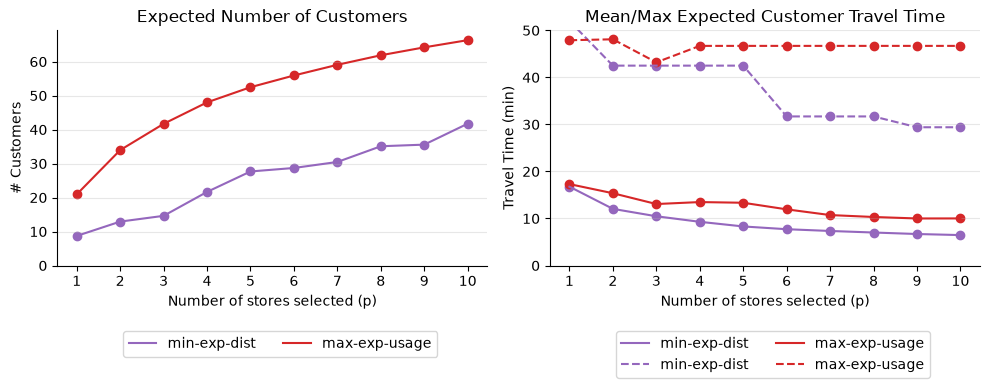

In [40]:
# The code below produces a plot of the expected number of customers average and worst-case customer travel distance
# for the two models incorporating predictions for each value of p
# TODO: Change the constants below to the correct columns in results_df for the expected number of customers and expected
#       average and worst-case distance columns changing the title/label columns if you used different units
EXP_CUSTOMER_COL = 'exp_customers'
MEAN_DIST_COL = 'exp_mean_time'
MAX_DIST_COL = 'max_time'

CUSTOMERS_TITLE, CUSTOMERS_YLABEL, CUSTOMERS_XLABEL = ('Expected Number of Customers', '# Customers', 'Number of stores selected (p)')
EXP_DIST_TITLE, EXP_DIST_YLABEL, EXP_DIST_XLABEL = ('Mean/Max Expected Customer Travel Time', 'Travel Time (min)', 'Number of stores selected (p)')

# Create the figure
fig = plt.figure(figsize=(10,4))

# Expected customers
plt.subplot(1,2,1)
for model in model_colors.keys():
    res = results_df.loc[model]

    plt.plot(res.index, res[EXP_CUSTOMER_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[EXP_CUSTOMER_COL], color=model_colors[model])

format_plot(title=CUSTOMERS_TITLE, ylabel=CUSTOMERS_YLABEL, xlabel=CUSTOMERS_XLABEL, legend_bbox=(0.9, -0.25))

# Expected travel distance
plt.subplot(1,2,2)
for model in model_colors.keys():
    res = results_df.loc[model]

    # Average customer travel time
    plt.plot(res.index, res[MEAN_DIST_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[MEAN_DIST_COL], color=model_colors[model])

    # Worst-case customer travel time
    plt.plot(res.index, res[MAX_DIST_COL], color=model_colors[model], linestyle='--', label=model)
    plt.scatter(res.index, res[MAX_DIST_COL], color=model_colors[model])

format_plot(title=EXP_DIST_TITLE, ylabel=EXP_DIST_YLABEL, xlabel=EXP_DIST_XLABEL, legend_bbox=(0.9, -0.25))
plt.ylim([0,50])
plt.show()

In [41]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
SOLUTION_COL = 'max-exp-usage-p5'

fig = plot_map(customers, stores, solution_col=SOLUTION_COL)
# fig.write_image('fig.png', scale=2)
fig.show()

In [42]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
SOLUTION_COL = 'max-exp-usage-p5'
TIME_COL = 'max-exp-usage-p5-time'

fig = plot_map(customers, stores, solution_col=SOLUTION_COL, time_col=TIME_COL, color_by="time")
fig.show()